# EXPT NO: 9 — TEXT CLASSIFICATION AND TEXT GENERATION USING TRANSFORMERS

**Student Roll No:** 24BAD108  


# PART A — DATASET PREPARATION AND TEXT PREPROCESSING



In [1]:
# Cell 1: Install required packages
%pip install -q "transformers>=4.44,<5.0" "datasets>=2.18" accelerate sentencepiece scikit-learn matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
# Cell 2: Import libraries and select device
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import TensorDataset, DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModelForSeq2SeqLM
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cpu
Device: cpu


In [3]:
# Cell 3: Load IMDb dataset (only train and test splits)
# Hugging Face IMDb contains review text and binary sentiment labels.
raw_train = load_dataset("stanfordnlp/imdb", split="train")
raw_test = load_dataset("stanfordnlp/imdb", split="test")

# Shuffle and select a smaller subset for quick training
TRAIN_LIMIT = min(1200, len(raw_train))
TEST_LIMIT = min(300, len(raw_test))
raw_train = raw_train.shuffle(seed=SEED).select(range(TRAIN_LIMIT))
raw_test = raw_test.shuffle(seed=SEED + 1).select(range(TEST_LIMIT))

print("Training subset size:", len(raw_train))
print("Test subset size:", len(raw_test))
print("Sample review:", raw_train[0]["text"][:400])
print("Sample label:", raw_train[0]["label"], "(0=negative, 1=positive)")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Training subset size: 1200
Test subset size: 300
Sample review: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compa
Sample label: 1 (0=negative, 1=positive)


In [4]:
# Cell 4: Inspect sentiment distribution
train_labels_all = np.array(raw_train["label"])
test_labels = np.array(raw_test["label"])

print("Training labels:")
print(pd.Series(train_labels_all).value_counts().sort_index().rename(index={0: "Negative", 1: "Positive"}))

print("\nTesting labels:")
print(pd.Series(test_labels).value_counts().sort_index().rename(index={0: "Negative", 1: "Positive"}))


Training labels:
Negative    603
Positive    597
Name: count, dtype: int64

Testing labels:
Negative    156
Positive    144
Name: count, dtype: int64


In [5]:
# Cell 5: Load compact pretrained BERT tokenizer and prepare splits
BERT_MODEL_ID = "prajjwal1/bert-tiny"
MAX_LENGTH = 96

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_ID)

all_train_texts = list(raw_train["text"])
all_train_labels = np.array(raw_train["label"], dtype=np.int64)
indices = np.arange(len(all_train_texts))
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=all_train_labels
)

train_texts = [all_train_texts[i] for i in train_indices]
val_texts = [all_train_texts[i] for i in val_indices]
train_labels = all_train_labels[train_indices]
val_labels = all_train_labels[val_indices]
test_texts = list(raw_test["text"])
test_labels = np.array(raw_test["label"], dtype=np.int64)

print("Train:", len(train_texts), "Validation:", len(val_texts), "Test:", len(test_texts))


config.json:   0%|          | 0.00/285 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Train: 960 Validation: 240 Test: 300


In [6]:
# Cell 6: Tokenize text with padding and truncation
def tokenize_texts(texts):
    return bert_tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

train_tokens = tokenize_texts(train_texts)
val_tokens = tokenize_texts(val_texts)
test_tokens = tokenize_texts(test_texts)

print("Tokenized input shape:", train_tokens["input_ids"].shape)
print("Attention mask shape:", train_tokens["attention_mask"].shape)


Tokenized input shape: torch.Size([960, 96])
Attention mask shape: torch.Size([960, 96])


In [7]:
# Cell 7: Convert tokens to PyTorch datasets and data loaders
def make_tensor_dataset(tokens, labels):
    return TensorDataset(
        tokens["input_ids"],
        tokens["attention_mask"],
        torch.tensor(labels, dtype=torch.long)
    )

BATCH_SIZE = 16 if torch.cuda.is_available() else 8
train_dataset = make_tensor_dataset(train_tokens, train_labels)
val_dataset = make_tensor_dataset(val_tokens, val_labels)
test_dataset = make_tensor_dataset(test_tokens, test_labels)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE * 2, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE * 2, shuffle=False)

print("Batch size:", BATCH_SIZE)
print("Number of training batches:", len(train_loader))


Batch size: 8
Number of training batches: 120


# PART B — FINE-TUNING BERT FOR TEXT CLASSIFICATION



In [8]:
# Cell 8: Load the BERT sequence-classification model
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_ID,
    num_labels=2
).to(device)

print("BERT model loaded:", BERT_MODEL_ID)
print("Model device:", next(bert_model.parameters()).device)


pytorch_model.bin:   0%|          | 0.00/17.8M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at prajjwal1/bert-tiny and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BERT model loaded: prajjwal1/bert-tiny
Model device: cpu


In [9]:
# Cell 9: Define evaluation helper
@torch.no_grad()
def evaluate_model(model, data_loader):
    model.eval()
    losses = []
    all_predictions = []
    all_labels = []

    for input_ids, attention_mask, labels in data_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        losses.append(outputs.loss.item())
        predictions = torch.argmax(outputs.logits, dim=1)
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().tolist())

    metrics = {
        "loss": float(np.mean(losses)) if losses else 0.0,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(all_labels, all_predictions, zero_division=0),
        "recall": recall_score(all_labels, all_predictions, zero_division=0),
        "f1": f1_score(all_labels, all_predictions, zero_division=0)
    }
    return metrics, np.array(all_labels), np.array(all_predictions)


In [10]:
# Cell 10: Fine-tune BERT quickly (one epoch)
from torch.optim import AdamW

EPOCHS = 1
LEARNING_RATE = 2e-5
optimizer = AdamW(bert_model.parameters(), lr=LEARNING_RATE)

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    bert_model.train()
    batch_losses = []

    for step, (input_ids, attention_mask, labels) in enumerate(train_loader, start=1):
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), max_norm=1.0)
        optimizer.step()
        batch_losses.append(loss.item())

        if step % 10 == 0 or step == len(train_loader):
            print(f"Epoch {epoch+1}/{EPOCHS} | Batch {step}/{len(train_loader)} | Loss {loss.item():.4f}")

    train_losses.append(float(np.mean(batch_losses)))
    val_metrics, _, _ = evaluate_model(bert_model, val_loader)
    val_losses.append(val_metrics["loss"])
    print(f"Epoch {epoch+1}: train loss={train_losses[-1]:.4f}, validation loss={val_losses[-1]:.4f}, validation accuracy={val_metrics['accuracy']:.4f}")

print("Fine-tuning complete.")


model.safetensors:   0%|          | 0.00/17.7M [00:00<?, ?B/s]

Epoch 1/1 | Batch 10/120 | Loss 0.7167
Epoch 1/1 | Batch 20/120 | Loss 0.6886
Epoch 1/1 | Batch 30/120 | Loss 0.6885
Epoch 1/1 | Batch 40/120 | Loss 0.6650
Epoch 1/1 | Batch 50/120 | Loss 0.6874
Epoch 1/1 | Batch 60/120 | Loss 0.6886
Epoch 1/1 | Batch 70/120 | Loss 0.6665
Epoch 1/1 | Batch 80/120 | Loss 0.7214
Epoch 1/1 | Batch 90/120 | Loss 0.6793
Epoch 1/1 | Batch 100/120 | Loss 0.6872
Epoch 1/1 | Batch 110/120 | Loss 0.7412
Epoch 1/1 | Batch 120/120 | Loss 0.6824
Epoch 1: train loss=0.6859, validation loss=0.6759, validation accuracy=0.6208
Fine-tuning complete.


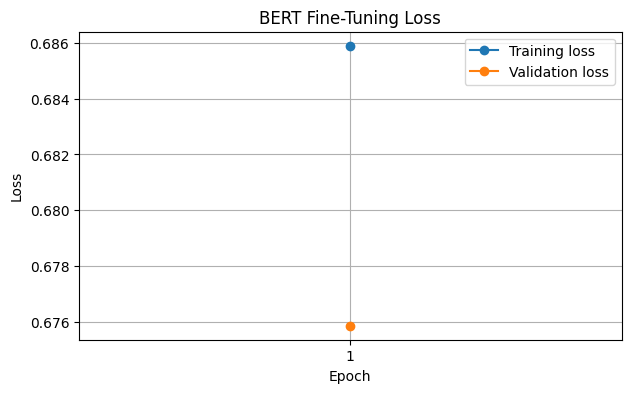

In [11]:
# Cell 11: Plot training and validation loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker="o", label="Training loss")
plt.plot(range(1, len(val_losses) + 1), val_losses, marker="o", label="Validation loss")
plt.title("BERT Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, len(train_losses) + 1))
plt.legend()
plt.grid(True)
plt.show()


Test metrics:
Loss: 0.6762
Accuracy: 0.6167
Precision: 0.6436
Recall: 0.4514
F1: 0.5306


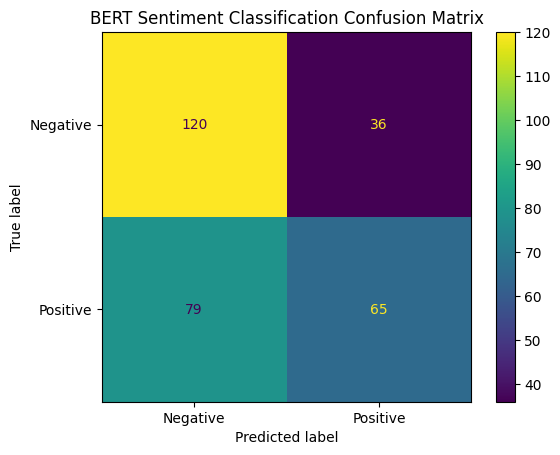

In [12]:
# Cell 12: Evaluate BERT on test subset
test_metrics, y_true, y_pred = evaluate_model(bert_model, test_loader)
print("Test metrics:")
for name, value in test_metrics.items():
    print(f"{name.capitalize()}: {value:.4f}")

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
display = ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"])
display.plot()
plt.title("BERT Sentiment Classification Confusion Matrix")
plt.show()


In [13]:
# Cell 13: Predict sentiment for new text inputs
@torch.no_grad()
def predict_sentiment(text):
    bert_model.eval()
    inputs = bert_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=MAX_LENGTH
    ).to(device)
    logits = bert_model(**inputs).logits
    probabilities = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    predicted_id = int(np.argmax(probabilities))
    label = "Positive" if predicted_id == 1 else "Negative"
    return label, probabilities

for sample in [
    "This movie was wonderful, moving, and very enjoyable.",
    "The movie was dull and disappointing. I did not enjoy it."
]:
    label, probabilities = predict_sentiment(sample)
    print("Review:", sample)
    print("Predicted sentiment:", label)
    print("Probabilities [negative, positive]:", np.round(probabilities, 4))
    print("-")


Review: This movie was wonderful, moving, and very enjoyable.
Predicted sentiment: Negative
Probabilities [negative, positive]: [0.5172 0.4828]
-
Review: The movie was dull and disappointing. I did not enjoy it.
Predicted sentiment: Negative
Probabilities [negative, positive]: [0.5514 0.4486]
-


In [14]:
# Cell 14: Save fine-tuned BERT model and tokenizer
BERT_SAVE_DIR = "bert_tiny_imdb_sentiment"
os.makedirs(BERT_SAVE_DIR, exist_ok=True)
bert_model.save_pretrained(BERT_SAVE_DIR)
bert_tokenizer.save_pretrained(BERT_SAVE_DIR)

print("Saved fine-tuned model and tokenizer to:", BERT_SAVE_DIR)


Saved fine-tuned model and tokenizer to: bert_tiny_imdb_sentiment


# PART C — SEQUENCE-TO-SEQUENCE TEXT GENERATION USING T5-SMALL



In [15]:
# Cell 15: Load T5-small and its tokenizer
T5_MODEL_ID = "google-t5/t5-small"
t5_tokenizer = AutoTokenizer.from_pretrained(T5_MODEL_ID)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(T5_MODEL_ID).to(device)
t5_model.eval()

print("T5 model loaded:", T5_MODEL_ID)


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5 model loaded: google-t5/t5-small


In [16]:
# Cell 16: Define a text generation function
@torch.no_grad()
def generate_summary(text, max_new_tokens=48, num_beams=2):
    prompt = "summarize: " + text.strip()
    inputs = t5_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(device)

    generated_ids = t5_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        num_beams=num_beams,
        do_sample=False,
        early_stopping=True
    )
    return t5_tokenizer.decode(generated_ids[0], skip_special_tokens=True)

print("Text generation function is ready.")


Text generation function is ready.


In [17]:
# Cell 17: Generate outputs for different input texts
input_texts = [
    "Artificial intelligence is a field of computer science that creates systems able to perform tasks that usually require human intelligence. Machine learning is a branch of AI that learns patterns from data. Deep learning uses multilayer neural networks and is widely used in vision, speech, and language applications.",
    "Renewable energy comes from sources that naturally replenish, including sunlight, wind, and flowing water. Solar panels convert sunlight into electricity, while wind turbines use moving air to generate power. Renewable energy can reduce reliance on fossil fuels, although storage and grid upgrades are often needed."
]

outputs = []
for i, input_text in enumerate(input_texts, start=1):
    summary = generate_summary(input_text, max_new_tokens=48, num_beams=2)
    outputs.append({"input": input_text, "summary": summary})
    print(f"EXAMPLE {i}")
    print("Input:", input_text)
    print("Generated summary:", summary)
    print("-" * 50)


EXAMPLE 1
Input: Artificial intelligence is a field of computer science that creates systems able to perform tasks that usually require human intelligence. Machine learning is a branch of AI that learns patterns from data. Deep learning uses multilayer neural networks and is widely used in vision, speech, and language applications.
Generated summary: machine learning is a branch of AI that learns patterns from data. deep learning is widely used in vision, speech, and language applications.
--------------------------------------------------
EXAMPLE 2
Input: Renewable energy comes from sources that naturally replenish, including sunlight, wind, and flowing water. Solar panels convert sunlight into electricity, while wind turbines use moving air to generate power. Renewable energy can reduce reliance on fossil fuels, although storage and grid upgrades are often needed.
Generated summary: solar panels convert sunlight into electricity. wind turbines use moving air to generate power.
------

In [18]:
# Cell 18: Compare generation settings on the same input
comparison_input = input_texts[0]
summary_beams_2 = generate_summary(comparison_input, max_new_tokens=40, num_beams=2)
summary_beams_4 = generate_summary(comparison_input, max_new_tokens=60, num_beams=4)

print("Input:", comparison_input)
print("\nBeam search (2 beams, max 40 new tokens):")
print(summary_beams_2)
print("\nBeam search (4 beams, max 60 new tokens):")
print(summary_beams_4)


Input: Artificial intelligence is a field of computer science that creates systems able to perform tasks that usually require human intelligence. Machine learning is a branch of AI that learns patterns from data. Deep learning uses multilayer neural networks and is widely used in vision, speech, and language applications.

Beam search (2 beams, max 40 new tokens):
machine learning is a branch of AI that learns patterns from data. deep learning is widely used in vision, speech, and language applications.

Beam search (4 beams, max 60 new tokens):
machine learning is a branch of AI that learns patterns from data. deep learning is widely used in vision, speech, and language applications.


In [19]:
# Cell 19: Save generated text outputs
with open("t5_generated_summaries.json", "w", encoding="utf-8") as file:
    json.dump(outputs, file, ensure_ascii=False, indent=2)

print("Generated outputs saved to t5_generated_summaries.json")


Generated outputs saved to t5_generated_summaries.json


# PART D — MODEL TESTING AND OUTPUT ANALYSIS



In [20]:
# Cell 20: Display evaluation summary and example predictions
print("BERT test evaluation summary")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nExample sentiment predictions")
review_samples = [
    "I loved the acting and the story was excellent.",
    "This was a terrible movie with weak writing."
]
for review in review_samples:
    label, probs = predict_sentiment(review)
    print(f"Text: {review}\nPredicted: {label}\nProbabilities: {np.round(probs, 3)}\n")

print("T5-generated outputs:")
for item in outputs:
    print("Summary:", item["summary"])


BERT test evaluation summary
loss: 0.6762
accuracy: 0.6167
precision: 0.6436
recall: 0.4514
f1: 0.5306

Example sentiment predictions
Text: I loved the acting and the story was excellent.
Predicted: Negative
Probabilities: [0.542 0.458]

Text: This was a terrible movie with weak writing.
Predicted: Negative
Probabilities: [0.523 0.477]

T5-generated outputs:
Summary: machine learning is a branch of AI that learns patterns from data. deep learning is widely used in vision, speech, and language applications.
Summary: solar panels convert sunlight into electricity. wind turbines use moving air to generate power.
